## Lab 4: FIR filters and envelopes

The goal of this lab is to connect the FIR filter ideas from the theory summary with the synthesis workflow from the previous labs. We will study two related ideas:

- a finite impulse response (FIR) filter as a weighted sum of past samples, and
- an envelope detector built from a rectifier followed by smoothing.

The theory summary on FIR filters introduces the key concepts behind convolution, impulse response, and the low-pass effect of a moving-average filter. The exercises below are designed to make those ideas concrete in both a toy example and in audio signals.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Audio, display

from util import load_audio, plot_spectrogram

### 1. FIR filters as weighted sums

An FIR filter computes the output as

$$
y[n] = \sum_{k=0}^{M} b_k x[n-k]
$$

where the coefficients $b_k$ define the filter. In the special case of a moving-average filter, all coefficients are equal to $1/(M+1)$ so the output is the average of $M+1$ input samples. This is exactly the operation implemented by convolution with an impulse response that is a short rectangular pulse.

A useful way to think about this is: the filter output at each instant is a local average of the input, so sharp changes get smoothed. That is why a moving-average filter is often used as a simple low-pass filter.

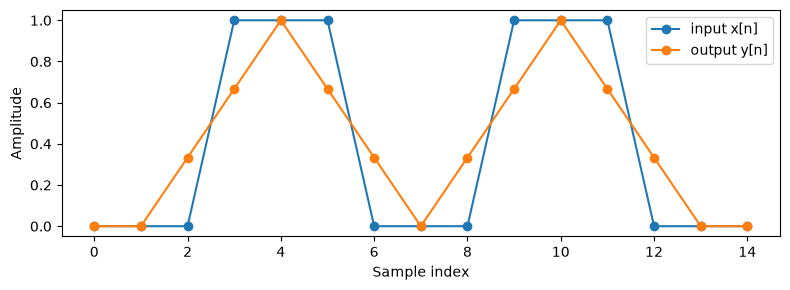

In [2]:
fs = 1
x = np.array([0, 0, 0, 1, 1, 1, 0, 0, 0, 1, 1, 1, 0, 0, 0], dtype=float)
b = np.array([1/3, 1/3, 1/3])
y = np.convolve(b, x, mode='same')

plt.figure(figsize=(8, 3))
plt.plot(x, 'o-', label='input x[n]')
plt.plot(y, 'o-', label='output y[n]')
plt.xlabel('Sample index')
plt.ylabel('Amplitude')
plt.legend()
plt.tight_layout()
plt.show()

#### 1.1 Questions

1. Which parts of the signal become smoother after filtering?
    - The sharp transitions, step edges and rapid sample-to-sample variations in the signal become smoother after filtering.

2. Why does the filtered output change more gradually than the original input?
    - Because the moving-average filter replaces each sample with the average of its local neighbors (M+1 samples), which flattens abrupt amplitude jumps and spreads changes over several samples.

3. What would happen to the smoothing effect if the filter used more coefficients?
    - Using more coefficients increases the smoothing effect, causing fast changes to blur even more and rounding off sharp corners further.


#### 1.2 Implement an averaging filter
Complete the function below so that it applies an $N$-point moving-average filter with `np.convolve` and returns a result with the same length as the input. Try different values of $N$.

In [3]:
def averaging_filter(x, N):
    x = np.asarray(x, dtype=float)
    b = np.ones(N) / N
    return np.convolve(x, b, mode='same')

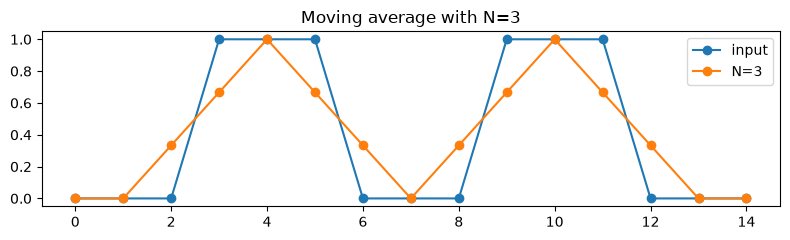

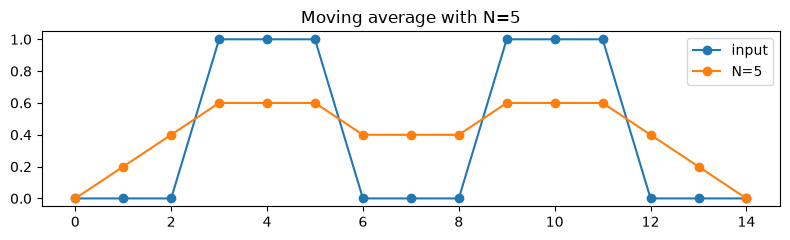

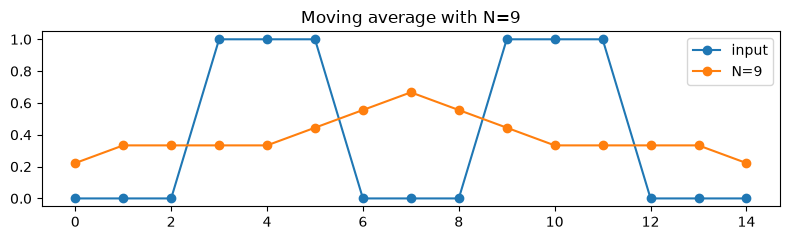

In [4]:
for N in [3, 5, 9]:
    y_N = averaging_filter(x, N)
    plt.figure(figsize=(8, 2.5))
    plt.plot(x, 'o-', label='input')
    plt.plot(y_N, 'o-', label=f'N={N}')
    plt.title(f'Moving average with N={N}')
    plt.legend()
    plt.tight_layout()
    plt.show()

#### 1.3 Questions

1. What happens to the output when $N$ becomes larger?
   - As N becomes larger, the output waveform becomes increasingly smooth, peak amplitudes are reduced and rapid fluctuations are smeared across time.

2. Why does the filter behave like a low-pass filter?
   - Because taking the average of nearby samples smooths out sharp and fast changes in the signal, which removes high frequencies and only lets the slow and smooth trends (low frequencies) pass through.

3. Which frequencies are attenuated more strongly: low frequencies or high frequencies? [note: be careful because we are visualizing time-domain]
   - High frequencies are attenuated much more strongly, as rapid oscillations cancel out when averaged within the window N.

### 2. Envelope detection with rectification and smoothing
An detector uses two blocks:
1. a full-wave rectifier, implemented with `np.abs(x)`, and
2. a smoothing filter, implemented with the averaging filter from above.

The rectifier removes the sign of the signal, turning oscillations into a positive waveform. The averaging stage then removes the rapid oscillations and keeps the slower rise and fall of the envelope.

#### 2.1 Add envelope detector
Modify the following functions to try a few different values of $N$ and compare the resulting envelope.

In [5]:
def envelope(x, N):
    x = np.asarray(x, dtype=float)
    rectified = np.abs(x)
    return averaging_filter(rectified, N)

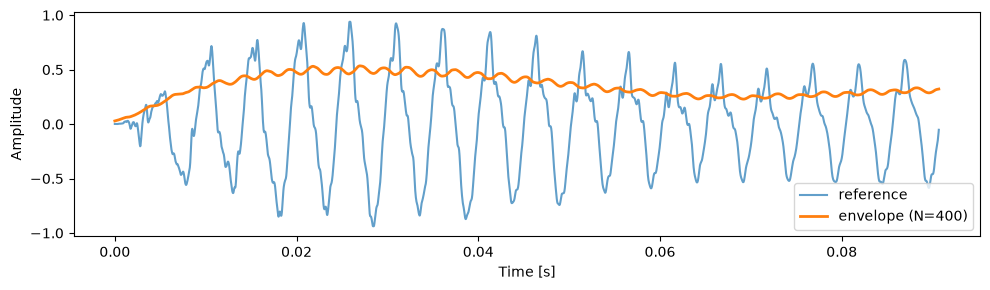

In [6]:
reference_audio, fs = load_audio('audio/reference.wav')
t = np.arange(len(reference_audio)) / fs

N = 400
env = envelope(reference_audio, N)

plt.figure(figsize=(10, 3))
plt.plot(t[:4000], reference_audio[:4000], alpha=0.7, label='reference')
plt.plot(t[:4000], env[:4000], linewidth=2, label=f'envelope (N={N})')
plt.xlabel('Time [s]')
plt.ylabel('Amplitude')
plt.legend()
plt.tight_layout()
plt.show()

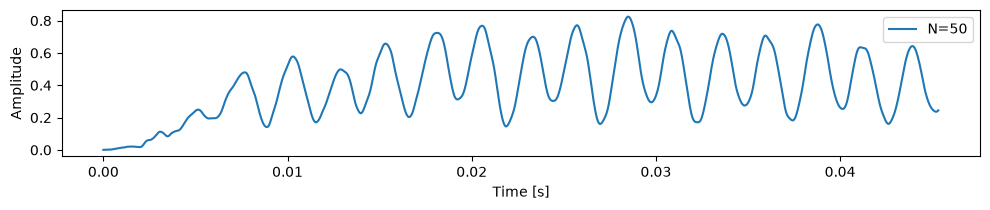

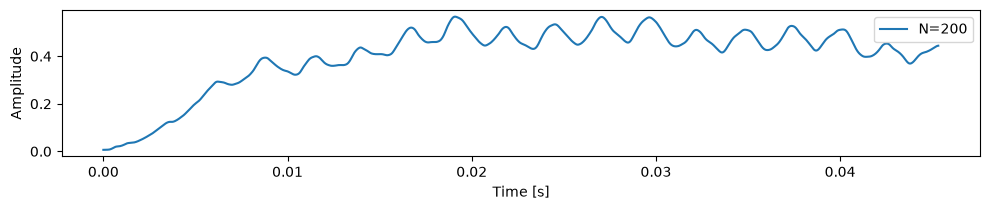

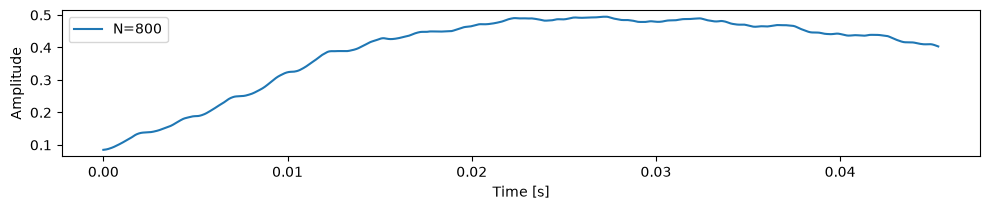

In [7]:
# Try a few filter sizes and inspect how the envelope changes
for N in [50, 200, 800]:
    env_N = envelope(reference_audio, N)
    plt.figure(figsize=(10, 2.2))
    plt.plot(t[:2000], env_N[:2000], label=f'N={N}')
    plt.xlabel('Time [s]')
    plt.ylabel('Amplitude')
    plt.legend()
    plt.tight_layout()
    plt.show()

# Try adding one or two more values of N here to see how the smoothing changes
# for example: [25, 100, 400, 1600]


#### 2.2 Questions

1. Why does the rectifier make the envelope easier to estimate?
   - Taking the absolute value (np.abs(x)) flips all negative amplitude swings to positive values. This turns the signal into a purely positive pulsating waveform, making it much easier for the subsequent moving-average filter to smooth out rapid zero-crossings and track the upper boundary of the sound.   

2. What happens if $N$ is very small?
   - If N is too small, the filter doesn't average over enough samples to eliminate the individual audio-frequency oscillations. The resulting envelope remains noisy and jagged.

3. What happens if $N$ is very large?
   - If N is too large, the averaging window spans too much time, causing the envelope to become overly smoothed and smeared. It blurs sharp attack transients and lags behind fast changes in volume.

### 3. Apply the envelope to a synthesized sound

Now we combine the harmonic synthesis idea from Lab 3 with the envelope detector from this lab. The goal is to make the synthesized signal look and sound more like the reference by multiplying the harmonic signal by a slowly varying envelope. Add the amplitude weights obtained in Lab 3.

#### 3.1 Add envelope

Add your own amplitude weights in the code cell below and try at least two different values of the smoothing window $N$.
You can compare how the synthesized sound changes when the envelope is smoother or less smooth.


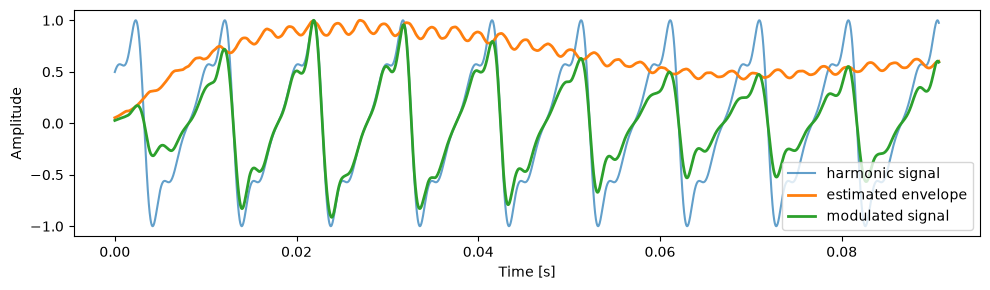

In [10]:
def synthesize(f0, phi, Ak, t):
    y = np.zeros_like(t, dtype=float)
    for k in range(1, len(Ak) + 1):
        y += Ak[k - 1] * np.cos(2 * np.pi * k * f0 * t + k * phi - (k - 1) * np.pi / 2)
    return y

f0 = 102.0
phi = -0.5
# add your own amplitude weights
weights = [1.0, 0.3981, 0.2818, 0.2239, 0.0562]
t = np.arange(len(reference_audio)) / fs

harmonic_signal = synthesize(f0, phi, weights, t)
harmonic_signal = harmonic_signal / np.max(np.abs(harmonic_signal))

# try different values of N
N = 400
envelope_signal = envelope(reference_audio, N)
envelope_signal = envelope_signal / np.max(np.abs(envelope_signal))

modulated_signal = harmonic_signal * envelope_signal
modulated_signal = modulated_signal / np.max(np.abs(modulated_signal))

plt.figure(figsize=(10, 3))
plt.plot(t[:4000], harmonic_signal[:4000], alpha=0.7, label='harmonic signal')
plt.plot(t[:4000], envelope_signal[:4000], linewidth=2, label='estimated envelope')
plt.plot(t[:4000], modulated_signal[:4000], linewidth=2, label='modulated signal')
plt.xlabel('Time [s]')
plt.ylabel('Amplitude')
plt.legend()
plt.tight_layout()
plt.show()

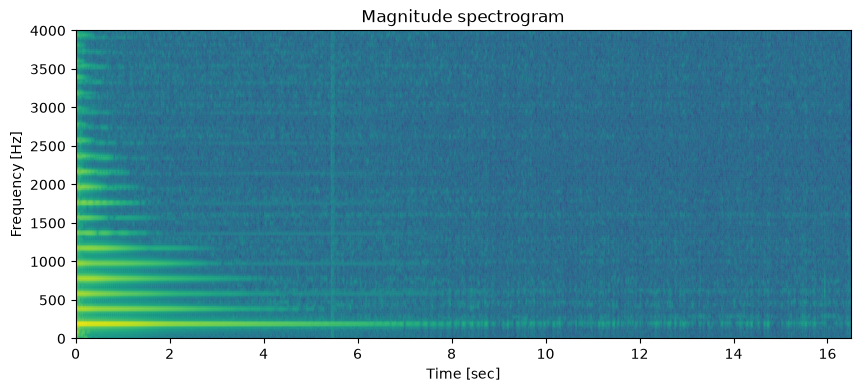

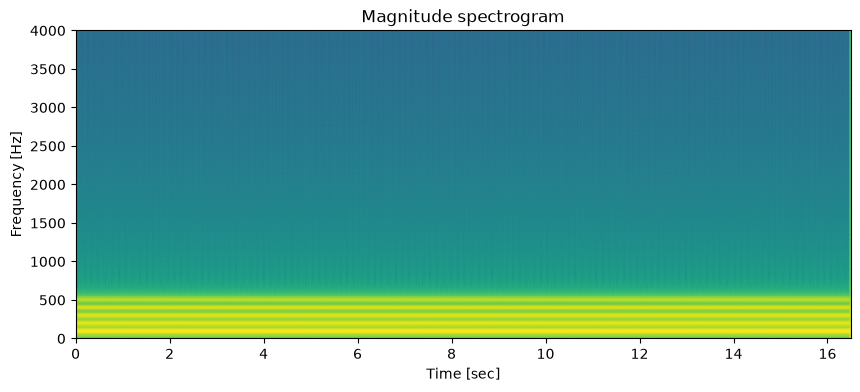

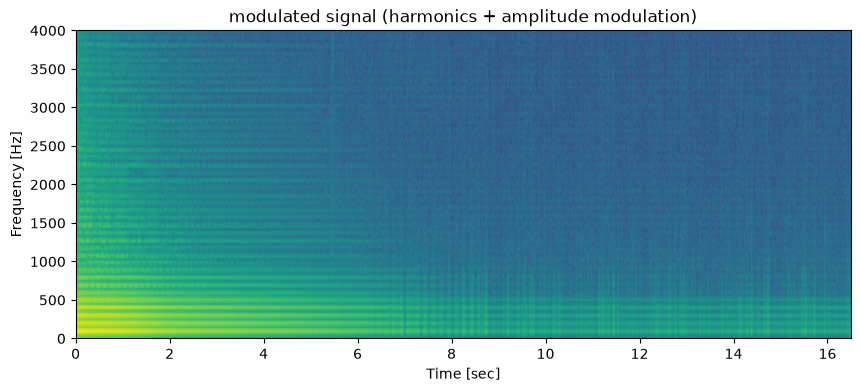

In [11]:
# The envelope introduces amplitude modulation, so the modulated signal will show more structure than a pure harmonic tone.
ax1 = plot_spectrogram(reference_audio, sr=fs, N=2048, H=256)
ax2 = plot_spectrogram(harmonic_signal, sr=fs, N=2048, H=256)
ax3 = plot_spectrogram(modulated_signal, sr=fs, N=2048, H=256)

ax1.set_ylim([0, 4000])
ax2.set_ylim([0, 4000])
ax3.set_ylim([0, 4000])
ax3.set_title('modulated signal (harmonics + amplitude modulation)')
plt.show()


In [12]:
from IPython.display import Audio, display

print("Reference sound")
display(Audio(reference_audio, rate=fs))

print("Harmonic sound")
display(Audio(harmonic_signal, rate=fs))

print("Modulated sound")
display(Audio(modulated_signal, rate=fs))


Reference sound


Harmonic sound


Modulated sound


#### 3.2 Questions

1. How does the envelope change the amplitude of the sound over time?
   - The envelope acts as a time-varying scale factor. It takes the constant-volume pure harmonic signal and forces its overall amplitude to naturally decay over time, recreating the realistic pluck attack and fade-out of the acoustic guitar string.

2. What is the main difference between the spectrogram of the pure harmonic signal and the spectrogram of the modulated signal?
   - The pure harmonic spectrogram (middle plot) shows completely static, infinitely long horizontal bands across time. The modulated signal's spectrogram (bottom plot) shows horizontal harmonic bands that gradually fade out in brightness over time, capturing the natural energy dissipation seen in the reference spectrogram (top plot).

3. Why does the modulated signal show more structure than the purely harmonic signal?
   - Multiplying the harmonics by the envelope introduces time-domain amplitude dynamics. This dynamic variation transforms a flat, static tone into an evolving musical note.

4. Why is the smoothing stage important for creating a realistic amplitude envelope?
   - Without smoothing, the envelope detector would track every rapid zero-crossing and oscillation of the audio waveform. The moving-average smoothing filter removes these high-frequency ripples, leaving only a clean, smooth curve that tracks the true overall volume outline.